In [1]:
# %%
# Experimento: NTv3 (modelo base, congelado) + classificador leve
# + controles + análise de acerto por identidade ao treino (MMseqs2)
# Entrada: arquivos .fa por classe em  <DATA_ROOT>/<dataset>/Train/  e  .../Test/
#          (um arquivo por classe, ex.: TIR.fa, LTR.fa, Non-TE.fa)
# Requisito para a seção 7: MMseqs2 instalado e acessível no PATH (comando `mmseqs`)
import os
import re
import time
import shutil
import hashlib
import subprocess
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import confusion_matrix, classification_report, f1_score
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForMaskedLM, AutoConfig

# %%
# =============================================
# CONFIGURAÇÃO
# =============================================
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando o dispositivo: {device}")

dataset = 'Dataset5'
DATA_ROOT = './Data'                             # ajuste para sua estrutura
TRAIN_DIR = os.path.join(DATA_ROOT, dataset, 'Train')
TEST_DIR = os.path.join(DATA_ROOT, dataset, 'Test')

MODEL_ID = "InstaDeepAI/NTv3_8M_pre"             # versões: 8M, 100M, 650M (sufixo _pre)
PESOS_ALEATORIOS = False                         # True = controle sem pré-treino
CAMADA = -1                                      # índice do hidden_state a usar

WIN = 4096                                       # tamanho da janela (nt)
STRIDE = 2048                                    # passo entre janelas (50% de sobreposição)
MAX_WINDOWS = 8                                  # máx. de janelas por sequência (controla custo)
BATCH_WIN = 16                                   # janelas por lote na extração

USAR_PESO_DE_CLASSE = False                      # True se o seu dataset for desbalanceado
ORDEM_EXIBICAO = None                            # ex.: ["LTR", "LINE", "CLASS II", "Non-TE"] ou None

# --- Análise de identidade (MMseqs2) ---
RODAR_MMSEQS = True                              # False = reaproveita o hits_*.tsv já gerado
MMSEQS_THREADS = 4
LIMIAR_ID = 0.8                                  # teste "honesto": só sequências com identidade < limiar
PASTA_ANALISE = './Data/analise_ntv3'

CACHE_DIR = './Data/embeddings_ntv3'
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(PASTA_ANALISE, exist_ok=True)
TAG = MODEL_ID.split('/')[-1] + ('_rand' if PESOS_ALEATORIOS else '') + f'_L{CAMADA}'

# %%
# =============================================
# 1. LEITURA DOS FASTA (um arquivo por classe)
# =============================================
EXTS = ('.fa', '.fasta', '.fna')


def ler_fasta(path):
    ids, seqs = [], []
    cur_id, cur = None, []
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            if line.startswith('>'):
                if cur_id is not None:
                    ids.append(cur_id)
                    seqs.append(''.join(cur))
                cur_id, cur = line[1:].split()[0], []
            else:
                cur.append(line)
    if cur_id is not None:
        ids.append(cur_id)
        seqs.append(''.join(cur))
    return ids, seqs


def limpar(seq):
    seq = seq.upper().replace('U', 'T')
    return re.sub(r'[^ACGTN]', 'N', seq)


def carregar_split(pasta, classes=None):
    arquivos = sorted(f for f in os.listdir(pasta) if f.lower().endswith(EXTS))
    nomes = [os.path.splitext(f)[0] for f in arquivos]
    if classes is None:
        classes = nomes
    else:
        extras = set(nomes) - set(classes)
        if extras:
            raise ValueError(f"Classes no {pasta} ausentes no treino: {extras}")
    ids, seqs, labels = [], [], []
    for f, nome in zip(arquivos, nomes):
        i, s = ler_fasta(os.path.join(pasta, f))
        ids += i
        seqs += [limpar(x) for x in s]
        labels += [classes.index(nome)] * len(s)
    return ids, seqs, np.array(labels, dtype=np.int64), classes


ids_tr, seqs_tr, y_tr_all, classes = carregar_split(TRAIN_DIR)
ids_te, seqs_te, y_te, _ = carregar_split(TEST_DIR, classes)
num_classes = len(classes)

print("Classes:", classes)
print("Treino:", {c: int((y_tr_all == i).sum()) for i, c in enumerate(classes)})
print("Teste :", {c: int((y_te == i).sum()) for i, c in enumerate(classes)})

/home/tom/Área de trabalho/GIGANTE/doutorado-topicos-emergentes/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Usando o dispositivo: cuda
Classes: ['LINE', 'LTR', 'Random', 'TIR']
Treino: {'LINE': 5700, 'LTR': 5700, 'Random': 5700, 'TIR': 5700}
Teste : {'LINE': 570, 'LTR': 570, 'Random': 570, 'TIR': 570}


Loading weights: 100%|██████████| 147/147 [00:00<00:00, 1605.71it/s]
[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


  0/4 janelas (2s)
Formato dos embeddings: (4, 256) | 2.1s para 4 sequências
Carregando cache: ./Data/embeddings_ntv3/NTv3_8M_pre_L-1_Dataset5_train.npy
Carregando cache: ./Data/embeddings_ntv3/NTv3_8M_pre_L-1_Dataset5_test.npy
Treino: (22800, 256) | Teste: (2280, 256)
Epoch 1: Train Loss = 0.4053, Train Acc = 0.8491, Val Loss = 0.2779, Val Acc = 0.8988
Epoch 2: Train Loss = 0.2702, Train Acc = 0.9010, Val Loss = 0.2139, Val Acc = 0.9178
Epoch 3: Train Loss = 0.2441, Train Acc = 0.9110, Val Loss = 0.2090, Val Acc = 0.9264
Epoch 4: Train Loss = 0.2242, Train Acc = 0.9164, Val Loss = 0.2031, Val Acc = 0.9240
Epoch 5: Train Loss = 0.2133, Train Acc = 0.9206, Val Loss = 0.1799, Val Acc = 0.9307
Epoch 6: Train Loss = 0.2071, Train Acc = 0.9239, Val Loss = 0.1792, Val Acc = 0.9329
Epoch 7: Train Loss = 0.2034, Train Acc = 0.9270, Val Loss = 0.2055, Val Acc = 0.9244
Epoch 8: Train Loss = 0.1919, Train Acc = 0.9298, Val Loss = 0.1717, Val Acc = 0.9364
Epoch 9: Train Loss = 0.1889, Train Acc = 

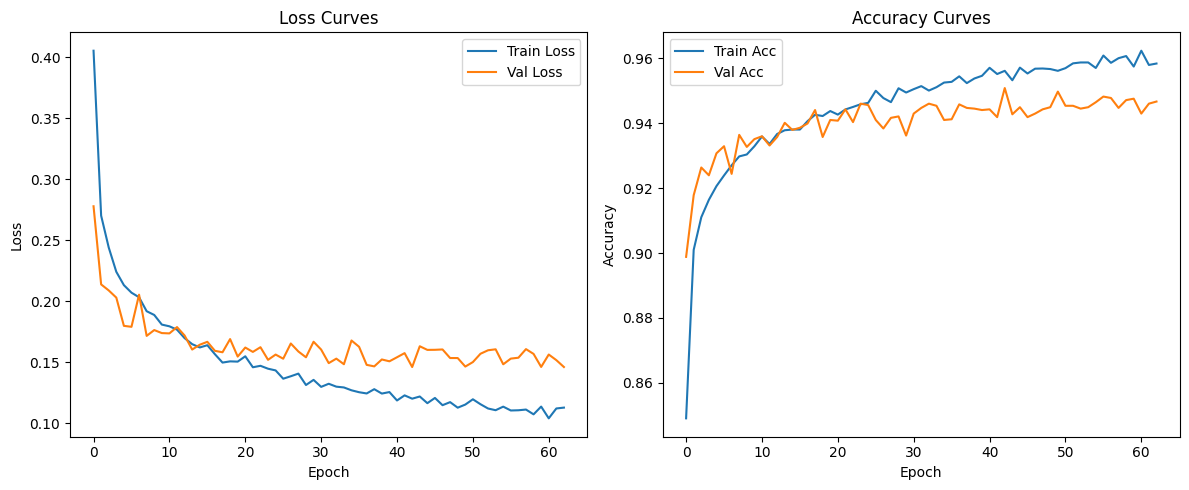

[[451  57  29  33]
 [ 50 342  80  98]
 [  2  50 504  14]
 [ 19  81  49 421]]


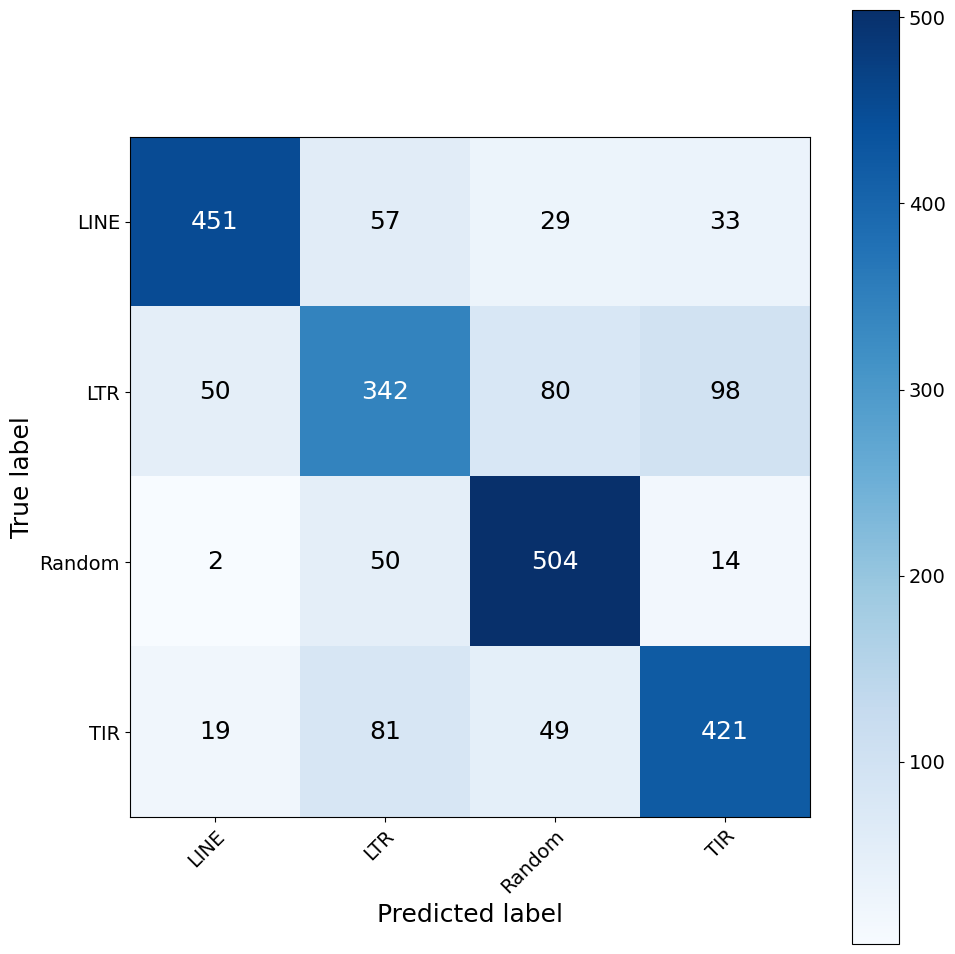

Acurácia por classe: ['LINE: 0.917', 'LTR: 0.818', 'Random: 0.902', 'TIR: 0.871']
Acurácia Macro: 0.877
Especificidade por classe: ['LINE: 0.958', 'LTR: 0.890', 'Random: 0.908', 'TIR: 0.915']
Especificidade Macro: 0.918
             acc  precision    recall  f1-score  specificity  support
LINE    0.916667   0.863985  0.791228  0.826007     0.958480    570.0
LTR     0.817544   0.645283  0.600000  0.621818     0.890058    570.0
Random  0.901754   0.761329  0.884211  0.818182     0.907602    570.0
TIR     0.871053   0.743816  0.738596  0.741197     0.915205    570.0
Mean    0.876754   0.753603  0.753509  0.751801     0.917836    570.0

F1 macro   : 0.7518
F1 ponderado: 0.7518
[NTv3 + LogReg]   F1 macro: 0.7014 | F1 pond.: 0.7014
[k-mer + LogReg]  F1 macro: 0.5738 | F1 pond.: 0.5738
[Rótulo embaralhado] F1 macro: 0.2188 (esperado: perto do acaso ~ 0.25)
Sequências do teste idênticas a alguma do treino: 0 de 2280
IDs repetidos entre treino e teste: 1


In [2]:


# %%
# =============================================
# 2. NTv3: janelas + embeddings (modelo congelado)
# =============================================
def carregar_modelo():
    tok = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
    if PESOS_ALEATORIOS:
        cfg = AutoConfig.from_pretrained(MODEL_ID, trust_remote_code=True)
        model = AutoModelForMaskedLM.from_config(cfg, trust_remote_code=True)
    else:
        model = AutoModelForMaskedLM.from_pretrained(MODEL_ID, trust_remote_code=True)
    return tok, model.to(device).eval()


def janelas(seq):
    if len(seq) <= WIN:
        return [seq]
    starts = list(range(0, len(seq) - WIN + 1, STRIDE))
    if starts[-1] + WIN < len(seq):
        starts.append(len(seq) - WIN)
    if len(starts) > MAX_WINDOWS:
        idx = np.linspace(0, len(starts) - 1, MAX_WINDOWS).round().astype(int)
        starts = [starts[i] for i in idx]
    return [seq[s:s + WIN] for s in starts]


@torch.no_grad()
def extrair_embeddings(seqs, tok, model):
    itens = [(i, w) for i, s in enumerate(seqs) for w in janelas(s)]
    ordem = sorted(range(len(itens)), key=lambda k: len(itens[k][1]))  # reduz padding
    soma, cont = None, np.zeros(len(seqs))
    t0 = time.time()
    for b in range(0, len(ordem), BATCH_WIN):
        idx = ordem[b:b + BATCH_WIN]
        enc = tok([itens[k][1] for k in idx], add_special_tokens=False, padding=True,
                  pad_to_multiple_of=128, return_tensors='pt')
        enc = {k: v.to(device) for k, v in enc.items() if k in ('input_ids', 'attention_mask')}
        out = model(**enc, output_hidden_states=True)
        h = out.hidden_states[CAMADA]
        pad_id = tok.pad_token_id
        if pad_id is None:
            mask = torch.ones_like(enc['input_ids']).unsqueeze(-1).float()
        else:
            mask = (enc['input_ids'] != pad_id).unsqueeze(-1).float()
        if mask.shape[1] != h.shape[1]:   # camadas intermediárias podem ter resolução menor
            mask = nn.functional.adaptive_max_pool1d(mask.transpose(1, 2), h.shape[1]).transpose(1, 2)
        vec = ((h.float() * mask).sum(1) / mask.sum(1).clamp(min=1)).cpu().numpy()
        if soma is None:
            soma = np.zeros((len(seqs), vec.shape[1]), dtype=np.float32)
        for j, k in enumerate(idx):
            soma[itens[k][0]] += vec[j]
            cont[itens[k][0]] += 1
        if (b // BATCH_WIN) % 50 == 0:
            print(f"  {b}/{len(ordem)} janelas ({time.time() - t0:.0f}s)")
    return soma / cont[:, None]


def obter_embeddings(nome_split, seqs):
    path = os.path.join(CACHE_DIR, f"{TAG}_{dataset}_{nome_split}.npy")
    if os.path.exists(path):
        print(f"Carregando cache: {path}")
        return np.load(path)
    tok, model = carregar_modelo()
    emb = extrair_embeddings(seqs, tok, model)
    np.save(path, emb)
    del model
    torch.cuda.empty_cache()
    return emb


# %%
# Teste rápido (rode antes do passo completo): confere formato e tempo
tok_t, model_t = carregar_modelo()
t0 = time.time()
e = extrair_embeddings(seqs_tr[:4], tok_t, model_t)
print("Formato dos embeddings:", e.shape, f"| {time.time() - t0:.1f}s para 4 sequências")
del model_t
torch.cuda.empty_cache()

# %%
X_tr_all = obter_embeddings('train', seqs_tr)
X_te = obter_embeddings('test', seqs_te)
print("Treino:", X_tr_all.shape, "| Teste:", X_te.shape)

# %%
# =============================================
# 3. Treino / validação (80/20 estratificado, como no seu script)
# =============================================
idx_all = np.arange(len(y_tr_all))
idx_tr, idx_val = train_test_split(idx_all, test_size=0.2, stratify=y_tr_all, random_state=42)
X_tr, y_tr = X_tr_all[idx_tr], y_tr_all[idx_tr]
X_val, y_val = X_tr_all[idx_val], y_tr_all[idx_val]

scaler = StandardScaler().fit(X_tr)
X_tr, X_val, X_te_s = scaler.transform(X_tr), scaler.transform(X_val), scaler.transform(X_te)


class EmbDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.X[i], self.y[i]


train_loader = DataLoader(EmbDataset(X_tr, y_tr), batch_size=32, shuffle=True)
val_loader = DataLoader(EmbDataset(X_val, y_val), batch_size=32)
test_loader = DataLoader(EmbDataset(X_te_s, y_te), batch_size=32)   # sem shuffle: ordem = seqs_te

# %%
# =============================================
# 4. Classificador leve sobre os embeddings
# =============================================
class MLPHead(nn.Module):
    def __init__(self, dim, hidden_dim=256, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, hidden_dim), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(hidden_dim, hidden_dim // 2), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(hidden_dim // 2, num_classes))

    def forward(self, x):
        return self.net(x)


model = MLPHead(X_tr.shape[1], 256, num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

if USAR_PESO_DE_CLASSE:
    cont = np.bincount(y_tr, minlength=num_classes).astype(np.float32)
    pesos = torch.tensor(cont.sum() / (num_classes * np.maximum(cont, 1)), device=device)
    criterion = nn.CrossEntropyLoss(weight=pesos)
else:
    criterion = nn.CrossEntropyLoss()


def acc_batch(out, y):
    return (out.argmax(1) == y).float().mean().item()


num_epochs, patience = 100, 20
best_val_loss, sem_melhora = float('inf'), 0
best_model_path = f"ntv3_head_{TAG}_{dataset}.pt"
train_losses, val_losses, train_accs, val_accs = [], [], [], []

for epoch in range(num_epochs):
    model.train()
    tl = ta = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        tl += loss.item()
        ta += acc_batch(out, y)
    tl /= len(train_loader)
    ta /= len(train_loader)

    model.eval()
    vl = va = 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            vl += criterion(out, y).item()
            va += acc_batch(out, y)
    vl /= len(val_loader)
    va /= len(val_loader)

    train_losses.append(tl); val_losses.append(vl)
    train_accs.append(ta); val_accs.append(va)
    print(f"Epoch {epoch+1}: Train Loss = {tl:.4f}, Train Acc = {ta:.4f}, "
          f"Val Loss = {vl:.4f}, Val Acc = {va:.4f}")

    if vl < best_val_loss:
        best_val_loss, sem_melhora = vl, 0
        torch.save(model.state_dict(), best_model_path)
    else:
        sem_melhora += 1
        if sem_melhora >= patience:
            print(f"Early stopping após {epoch+1} épocas")
            break

# %%
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss'); plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.title('Loss Curves')
plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Acc'); plt.plot(val_accs, label='Val Acc')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.title('Accuracy Curves')
plt.tight_layout()
plt.show()

# %%
# =============================================
# 5. Avaliação no teste
# =============================================
model.load_state_dict(torch.load(best_model_path))
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        all_preds.extend(model(x.to(device)).argmax(1).cpu().numpy())
        all_labels.extend(y.numpy())
all_preds, all_labels = np.array(all_preds), np.array(all_labels)
assert (all_labels == y_te).all(), "Ordem do teste não confere com seqs_te"

# Ordem de exibição (mesma para matriz e métricas)
if ORDEM_EXIBICAO is not None:
    ordem_idx = [classes.index(c) for c in ORDEM_EXIBICAO]
else:
    ordem_idx = list(range(num_classes))
nomes_exib = [classes[i] for i in ordem_idx]

cm = confusion_matrix(all_labels, all_preds, labels=ordem_idx)
print(cm)

fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
ax.set_xlabel('Predicted label', fontsize=18)
ax.set_ylabel('True label', fontsize=18)
ax.set_xticks(np.arange(len(nomes_exib)))
ax.set_yticks(np.arange(len(nomes_exib)))
ax.set_xticklabels(nomes_exib, fontsize=14)
ax.set_yticklabels(nomes_exib, fontsize=14)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for t in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, t, f"{int(cm[t, j])}", ha="center", va="center",
                color="white" if t == j else "black", fontsize=18)
cbar = ax.figure.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=14)
plt.tight_layout()
plt.show()

# %%
metrics = classification_report(all_labels, all_preds, labels=ordem_idx,
                                target_names=nomes_exib, output_dict=True, zero_division=0)
metrics_df = pd.DataFrame(metrics).transpose()


def accuracy_by_class(cm):
    accs = []
    for i in range(cm.shape[0]):
        TP = cm[i, i]
        FP = cm[:, i].sum() - TP
        FN = cm[i, :].sum() - TP
        TN = cm.sum() - TP - FP - FN
        total = TP + TN + FP + FN
        accs.append((TP + TN) / total if total > 0 else 0.0)
    return accs


def specificity(cm):
    out = []
    for i in range(cm.shape[0]):
        FP = cm[:, i].sum() - cm[i, i]
        TN = cm.sum() - cm[i, :].sum() - cm[:, i].sum() + cm[i, i]
        out.append(TN / (TN + FP) if (TN + FP) > 0 else 0.0)
    return out


def format_by_class(vals, names):
    return [f'{names[i]}: {v:.3f}' for i, v in enumerate(vals)]


acc_by_class = accuracy_by_class(cm)
spec_by_class = specificity(cm)
print("Acurácia por classe:", format_by_class(acc_by_class, nomes_exib))
print(f"Acurácia Macro: {np.mean(acc_by_class):.3f}")
print("Especificidade por classe:", format_by_class(spec_by_class, nomes_exib))
print(f"Especificidade Macro: {np.mean(spec_by_class):.3f}")

df_new = metrics_df.loc[nomes_exib].copy()
df_new['specificity'] = spec_by_class
df_new['acc'] = acc_by_class
df_new = df_new.reindex(columns=['acc', 'precision', 'recall', 'f1-score', 'specificity', 'support'])
df_new = pd.concat([df_new, pd.DataFrame([df_new.mean(numeric_only=True)], index=['Mean'])])
print(df_new)

print(f"\nF1 macro   : {f1_score(all_labels, all_preds, average='macro'):.4f}")
print(f"F1 ponderado: {f1_score(all_labels, all_preds, average='weighted'):.4f}")
df_new.to_csv(f"resultados_{TAG}_{dataset}.csv")

# %%
# =============================================
# 6. Controles (mesmo treino/teste)
#    a) regressão logística nos embeddings do NTv3
#    b) k-meros (k=5) + regressão logística
#    c) rótulos embaralhados (deve ficar perto do acaso; se não, há bug)
# =============================================
lr = LogisticRegression(max_iter=2000).fit(X_tr, y_tr)
pred_lr = lr.predict(X_te_s)
print(f"[NTv3 + LogReg]   F1 macro: {f1_score(y_te, pred_lr, average='macro'):.4f} | "
      f"F1 pond.: {f1_score(y_te, pred_lr, average='weighted'):.4f}")

vec = CountVectorizer(analyzer='char', ngram_range=(5, 5), lowercase=False)
Xk_all = normalize(vec.fit_transform([seqs_tr[i] for i in idx_tr]), norm='l1')
Xk_te = normalize(vec.transform(seqs_te), norm='l1')
sc_k = StandardScaler(with_mean=False).fit(Xk_all)
lr_k = LogisticRegression(max_iter=2000).fit(sc_k.transform(Xk_all), y_tr)
pred_kmer = lr_k.predict(sc_k.transform(Xk_te))
print(f"[k-mer + LogReg]  F1 macro: {f1_score(y_te, pred_kmer, average='macro'):.4f} | "
      f"F1 pond.: {f1_score(y_te, pred_kmer, average='weighted'):.4f}")

rng = np.random.default_rng(0)
lr_0 = LogisticRegression(max_iter=2000).fit(X_tr, rng.permutation(y_tr))
pred_0 = lr_0.predict(X_te_s)
print(f"[Rótulo embaralhado] F1 macro: {f1_score(y_te, pred_0, average='macro'):.4f} "
      f"(esperado: perto do acaso ~ {1 / num_classes:.2f})")

# %%
# =============================================
# 7. ANÁLISE DE VAZAMENTO: acerto por identidade ao treino (MMseqs2)
#    Pergunta: o modelo acerta porque aprendeu a classificar ou porque o
#    teste tem sequências quase iguais às do treino?
# =============================================
# 7.0 Duplicatas exatas e IDs repetidos entre treino e teste
md5 = lambda s: hashlib.md5(s.encode()).hexdigest()
set_tr = {md5(s) for s in seqs_tr}
dup_exata = np.array([md5(s) in set_tr for s in seqs_te])
print(f"Sequências do teste idênticas a alguma do treino: {dup_exata.sum()} de {len(seqs_te)}")
print(f"IDs repetidos entre treino e teste: {len(set(ids_tr) & set(ids_te))}")




mmseqs easy-search ./Data/analise_ntv3/test.fa ./Data/analise_ntv3/train.fa ./Data/analise_ntv3/hits_Dataset5.tsv ./Data/analise_ntv3/tmp --search-type 3 --strand 2 -s 7.5 --min-seq-id 0.3 -c 0.5 --format-output query,target,fident,qcov 

In [ ]:
PASTA_ANALISE = './Data/analise_ntv3'
RODAR_MMSEQS = True
mmseqs_ok = True
dataset = 'Dataset5'

# 7.1 Busca MMseqs2 (nucleotídeos, duas fitas). Usamos IDs numéricos (te_i / tr_j)
#     para evitar problemas com os caracteres especiais dos cabeçalhos originais.
hits_path = os.path.join(PASTA_ANALISE, f'hits_{dataset}.tsv')


def escrever_fasta(path, seqs, prefixo):
    with open(path, 'w') as f:
        for i, s in enumerate(seqs):
            f.write(f">{prefixo}{i}\n{s}\n")

fa_te = os.path.join(PASTA_ANALISE, f'test_{dataset}.fa')
fa_tr = os.path.join(PASTA_ANALISE, f'train_{dataset}.fa')
escrever_fasta(fa_te, seqs_te, 'te_')
escrever_fasta(fa_tr, seqs_tr, 'tr_')
tmp = os.path.join(PASTA_ANALISE, 'tmp')
shutil.rmtree(tmp, ignore_errors=True)


Acerto por faixa de identidade máxima ao treino:
            n  NTv3 + MLP  NTv3 + LogReg  k-mer + LogReg  \
sem hit  2150       0.744          0.693           0.567   
<=0.7      13       0.769          0.692           0.615   
0.7-0.8    33       1.000          0.909           0.879   
0.8-0.9    32       0.844          0.812           0.625   
>0.9       52       0.942          0.942           0.788   

         Melhor hit (homologia)  
sem hit                     NaN  
<=0.7                     1.000  
0.7-0.8                   1.000  
0.8-0.9                   0.969  
>0.9                      1.000  


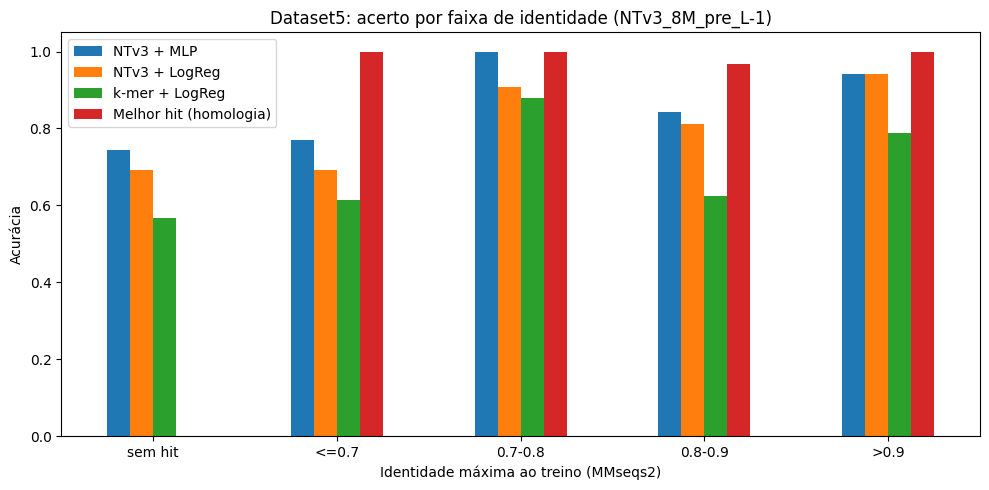


Sequências com identidade < 0.8: 2196 de 2280
Por classe (restantes): {'LINE': 525, 'LTR': 554, 'Random': 570, 'TIR': 547}

Método                 F1 macro (todos)    F1 macro (<0.8)
NTv3 + MLP                       0.7518             0.7459
NTv3 + LogReg                    0.7014             0.6940
k-mer + LogReg                   0.5738             0.5667

Arquivos salvos em ./Data/analise_ntv3


In [ ]:
hits = pd.read_csv(hits_path, sep='\t', names=['q', 't', 'fident', 'qcov'])
hits = hits[hits.qcov >= 0.5]                                   # descarta alinhamentos curtos
hits = hits.sort_values('fident', ascending=False).drop_duplicates('q')   # melhor hit por consulta
qi = hits.q.str.replace('te_', '', regex=False).astype(int).values
ti = hits.t.str.replace('tr_', '', regex=False).astype(int).values

max_id = np.zeros(len(seqs_te))                 # 0 = sem hit
max_id[qi] = hits.fident.values
rotulo_hit = np.full(len(seqs_te), -1)          # classe do melhor hit no treino
rotulo_hit[qi] = y_tr_all[ti]

faixas = [-0.01, 0.0, 0.7, 0.8, 0.9, 1.0]
nomes_faixa = ['sem hit', '<=0.7', '0.7-0.8', '0.8-0.9', '>0.9']
faixa = pd.cut(max_id, faixas, labels=nomes_faixa)

metodos = {
    'NTv3 + MLP': all_preds,
    'NTv3 + LogReg': pred_lr,
    'k-mer + LogReg': pred_kmer,
}

tabela = pd.DataFrame({'n': pd.Series(faixa).value_counts().reindex(nomes_faixa)})
for nome, p in metodos.items():
    tabela[nome] = pd.Series(p == y_te).groupby(faixa, observed=False).mean().reindex(nomes_faixa)
# Baseline de homologia: classe do melhor hit (só onde existe hit)
acerto_hit = np.where(max_id > 0, rotulo_hit == y_te, np.nan)
tabela['Melhor hit (homologia)'] = pd.Series(acerto_hit).groupby(faixa, observed=False).mean().reindex(nomes_faixa)

print("\nAcerto por faixa de identidade máxima ao treino:")
print(tabela.round(3))
tabela.to_csv(os.path.join(PASTA_ANALISE, f'acerto_por_faixa_{TAG}_{dataset}.csv'))

ax = tabela.drop(columns='n').plot.bar(figsize=(10, 5), rot=0)
ax.set_xlabel('Identidade máxima ao treino (MMseqs2)')
ax.set_ylabel('Acurácia')
ax.set_ylim(0, 1.05)
ax.set_title(f'{dataset}: acerto por faixa de identidade ({TAG})')
plt.tight_layout()
plt.show()

# 7.2 Teste "honesto": só sequências sem parente próximo no treino
m = max_id < LIMIAR_ID
print(f"\nSequências com identidade < {LIMIAR_ID}: {m.sum()} de {len(y_te)}")
print("Por classe (restantes):",
        {c: int(((y_te == i) & m).sum()) for i, c in enumerate(classes)})
labs = np.unique(y_te[m])
print(f"\n{'Método':<20} {'F1 macro (todos)':>18} {'F1 macro (<' + str(LIMIAR_ID) + ')':>18}")
for nome, p in metodos.items():
    f_all = f1_score(y_te, p, average='macro')
    f_sub = f1_score(y_te[m], p[m], average='macro', labels=labs, zero_division=0)
    print(f"{nome:<20} {f_all:>18.4f} {f_sub:>18.4f}")

# 7.3 Salva as predições com a identidade de cada sequência
pd.DataFrame({
        'id': ids_te, 'real': y_te, 'pred_mlp': all_preds, 'pred_lr': pred_lr,
        'pred_kmer': pred_kmer, 'max_id': max_id, 'faixa': faixa.astype(str),
        'classe_real': [classes[i] for i in y_te],
        'classe_pred_mlp': [classes[i] for i in all_preds],
    }).to_csv(os.path.join(PASTA_ANALISE, f'predicoes_{TAG}_{dataset}.csv'), index=False)
print(f"\nArquivos salvos em {PASTA_ANALISE}")